# 04 — `NeuroKit2` 500 Hz Delineation, Rhythm Sanity & Clinical Biomarkers

Because Georgia 12-Lead ECG is natively sampled at **`500 Hz`** (5× finer temporal resolution than PTB-XL's `100 Hz` soft segmentations), algorithmic wave delineation via **`NeuroKit2`** (`ecg_clean` + `ecg_peaks` + `ecg_delineate(method="dwt")`) can extract sharp fiducial landmarks directly on Lead II.

This notebook runs `NeuroKit2` across a stratified cohort (`N = 280` ECGs spanning `NSR`, `SB`, `STach`, `AF`, `IAVB`, `LBBB`, `RBBB`, and `LQT`) to audit:
1. **Rhythm-Label vs Waveform Heart Rate & RR Variability (`CV_RR`)**: Checking `SB` (`<60 BPM`), `STach` (`>100 BPM`), and `AF` (elevated `CV_RR`) — catching mislabeled rhythm records!
2. **Clinical Interval Validation**: Checking `NeuroKit2`-delineated **QRS duration** (`LBBB`/`RBBB` $\ge 120\text{ ms}$), **PR interval** (`IAVB` $> 200\text{ ms}$), and **QTc (Bazett)** (`LQT`).
3. **`NeuroKit2` Failure & `AF` P-Wave Hallucination Rate at `500 Hz`**.
4. **Side-by-Side Visual Delineation Overlays** on `NSR`, `IAVB`, `LBBB`, and `AF` waveforms.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "georgia_ecg" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate georgia_ecg/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from georgia_ecg import GeorgiaECGDataset

GEORGIA_DIR = REPO_ROOT / "georgia_ecg"
DATA_DIR = GEORGIA_DIR / "data"
LEADS = GeorgiaECGDataset.LEADS

df = pd.read_csv(GEORGIA_DIR / "quality" / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")
print(f"Loaded {len(df):,} Georgia 12-Lead ECG records from error_labels.csv")

import neurokit2 as nk

print(f"NeuroKit2 version: {nk.__version__}")
valid_df = df[(df["err_file_missing_or_corrupt"] == 0) & (df["n_samples"] >= 2500)].copy()

def delineate_nk2_500(rec_id: str) -> dict:
    sig, _ = wfdb.rdsamp(str(DATA_DIR / valid_df.loc[rec_id, "record_path"]))
    w_l2 = np.nan_to_num(sig[:, 1])
    try:
        cleaned = nk.ecg_clean(w_l2, sampling_rate=500, method="neurokit")
        _, r_info = nk.ecg_peaks(cleaned, sampling_rate=500, correct_artifacts=False)
        rpeaks = np.asarray(r_info.get("ECG_R_Peaks", []), dtype=int)
        if len(rpeaks) < 4:
            return {"record_id": rec_id, "failed": 1}
        rr_sec = np.diff(rpeaks) / 500.0
        hr_bpm = float(60.0 / np.median(rr_sec))
        cv_rr  = float(np.std(rr_sec) / (np.mean(rr_sec) + 1e-8))

        _, waves = nk.ecg_delineate(cleaned, rpeaks, sampling_rate=500, method="dwt")

        def pair_dur_ms(k_start: str, k_end: str, lo: float, hi: float) -> float:
            s_arr, e_arr = waves.get(k_start, []), waves.get(k_end, [])
            durs = []
            for a, b in zip(s_arr, e_arr):
                if pd.notna(a) and pd.notna(b):
                    d = (float(b) - float(a)) * 2.0  # 2 ms/sample @ 500 Hz
                    if lo <= d <= hi:
                        durs.append(d)
            return float(np.median(durs)) if durs else np.nan

        pr_ms  = pair_dur_ms("ECG_P_Onsets", "ECG_R_Onsets", 60, 450)
        qrs_ms = pair_dur_ms("ECG_R_Onsets", "ECG_R_Offsets", 40, 260)
        qt_ms  = pair_dur_ms("ECG_R_Onsets", "ECG_T_Offsets", 200, 700)
        qtc_ms = float(qt_ms / np.sqrt(np.median(rr_sec))) if pd.notna(qt_ms) else np.nan
        p_per_beat = sum(1 for v in waves.get("ECG_P_Peaks", []) if pd.notna(v)) / max(len(rpeaks), 1)

        return {
            "record_id": rec_id, "failed": 0, "hr_bpm": hr_bpm, "cv_rr": cv_rr,
            "pr_ms": pr_ms, "qrs_ms": qrs_ms, "qtc_ms": qtc_ms, "p_per_beat": p_per_beat,
        }
    except Exception:
        return {"record_id": rec_id, "failed": 1}

rng = np.random.default_rng(42)
cohorts = {
    "NSR":   "426783006",
    "SB":    "426177001",
    "STach": "427084000",
    "AF":    "164889003",
    "IAVB":  "270492004",
    "LBBB":  "164909002",
    "RBBB":  "59118001",
    "LQT":   "111975006",
}

bio_rows = []
for grp, code_str in cohorts.items():
    pool = valid_df.index[valid_df["snomed_codes"].str.contains(code_str)]
    chosen = rng.choice(pool.to_numpy(), size=min(40, len(pool)), replace=False)
    for rid in chosen:
        r = delineate_nk2_500(str(rid))
        r["group"] = grp
        bio_rows.append(r)

bio_df = pd.DataFrame(bio_rows)
print("=== NeuroKit2 500 Hz Delineation Biomarkers Across Georgia CinC 2020 Classes ===")
display(
    bio_df.groupby("group").agg(
        n=("record_id", "count"),
        fail_pct=("failed", lambda s: round(s.mean() * 100, 1)),
        hr_bpm=("hr_bpm", "median"),
        cv_rr=("cv_rr", "median"),
        pr_ms=("pr_ms", "median"),
        qrs_ms=("qrs_ms", "median"),
        qtc_ms=("qtc_ms", "median"),
        nk2_p_per_beat=("p_per_beat", "median"),
    ).round(2)
)

Loaded 10,344 Georgia 12-Lead ECG records from error_labels.csv


NeuroKit2 version: 0.3.0


=== NeuroKit2 500 Hz Delineation Biomarkers Across Georgia CinC 2020 Classes ===


,n,fail_pct,hr_bpm,cv_rr,pr_ms,qrs_ms,qtc_ms,nk2_p_per_beat
group,,,,,,,,
AF,40,2.5,90.91,0.18,121.0,178.0,490.27,1.0
IAVB,40,0.0,68.49,0.02,159.5,165.5,495.25,1.0
LBBB,40,0.0,74.81,0.02,121.0,176.0,490.23,1.0
LQT,40,0.0,75.57,0.01,109.0,168.0,462.79,1.0
NSR,40,0.0,71.94,0.02,111.0,140.0,449.33,1.0
RBBB,40,0.0,69.24,0.02,108.5,182.0,472.40,1.0
SB,40,0.0,54.95,0.03,83.0,199.0,481.01,1.0
STach,40,0.0,111.95,0.01,96.0,167.0,473.39,1.0


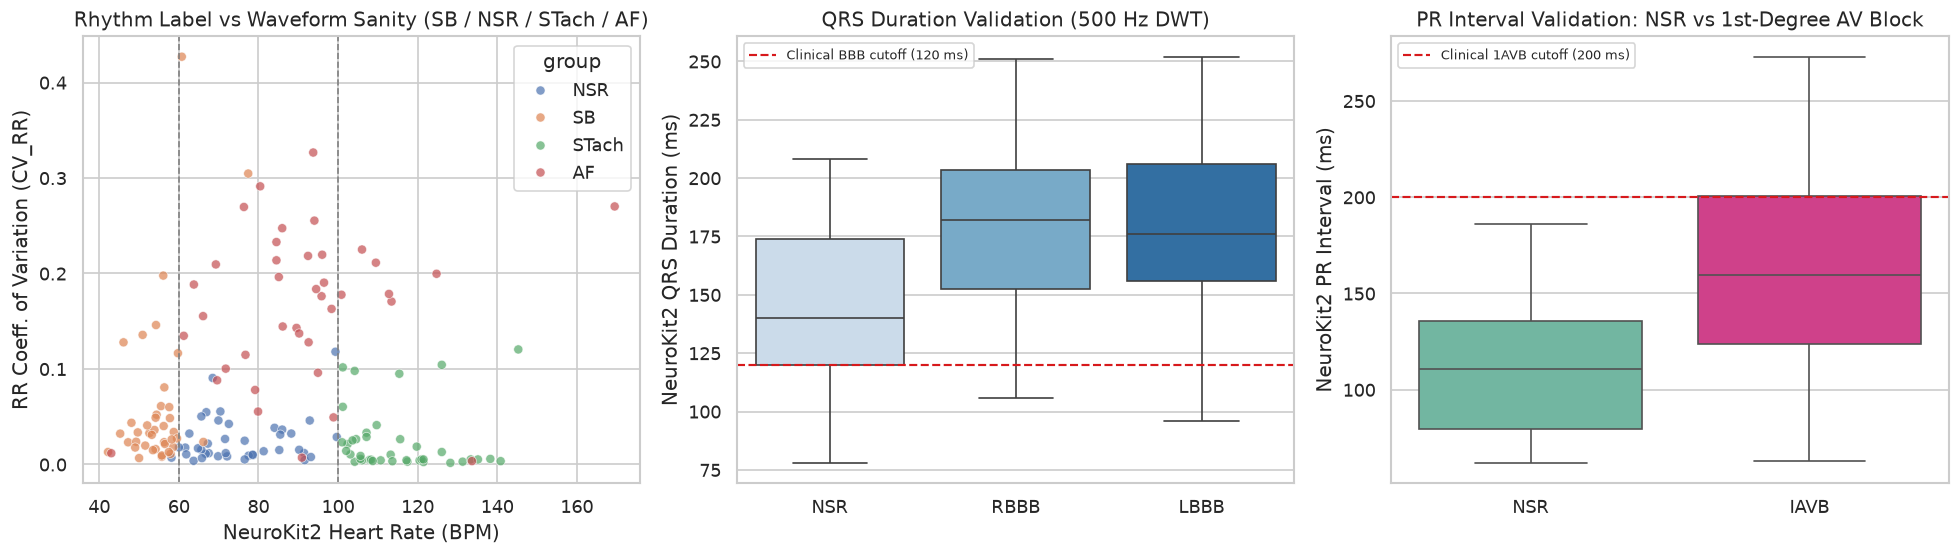

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel A: Heart Rate vs RR Irregularity (Rhythm Sanity)
rhy = bio_df[bio_df["group"].isin(["NSR", "SB", "STach", "AF"]) & (bio_df["failed"] == 0)]
sns.scatterplot(data=rhy[rhy["cv_rr"] < 0.6], x="hr_bpm", y="cv_rr", hue="group", s=30, alpha=0.7, ax=axes[0])
axes[0].axvline(60, color="gray", ls="--", lw=1)
axes[0].axvline(100, color="gray", ls="--", lw=1)
axes[0].set_xlabel("NeuroKit2 Heart Rate (BPM)")
axes[0].set_ylabel("RR Coeff. of Variation (CV_RR)")
axes[0].set_title("Rhythm Label vs Waveform Sanity (SB / NSR / STach / AF)")

# Panel B: QRS Duration across NSR vs LBBB & RBBB
qrs_sub = bio_df[bio_df["group"].isin(["NSR", "RBBB", "LBBB"]) & bio_df["qrs_ms"].notna()]
sns.boxplot(data=qrs_sub, x="group", y="qrs_ms", order=["NSR", "RBBB", "LBBB"], palette="Blues", ax=axes[1])
axes[1].axhline(120, color="#d7191c", ls="--", lw=1.3, label="Clinical BBB cutoff (120 ms)")
axes[1].set_ylabel("NeuroKit2 QRS Duration (ms)")
axes[1].set_xlabel("")
axes[1].set_title("QRS Duration Validation (500 Hz DWT)")
axes[1].legend(fontsize=8)

# Panel C: PR Interval (NSR vs IAVB)
pr_sub = bio_df[bio_df["group"].isin(["NSR", "IAVB"]) & bio_df["pr_ms"].notna()]
sns.boxplot(data=pr_sub, x="group", y="pr_ms", order=["NSR", "IAVB"], palette=["#66c2a5", "#e7298a"], ax=axes[2])
axes[2].axhline(200, color="#d7191c", ls="--", lw=1.3, label="Clinical 1AVB cutoff (200 ms)")
axes[2].set_ylabel("NeuroKit2 PR Interval (ms)")
axes[2].set_xlabel("")
axes[2].set_title("PR Interval Validation: NSR vs 1st-Degree AV Block")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

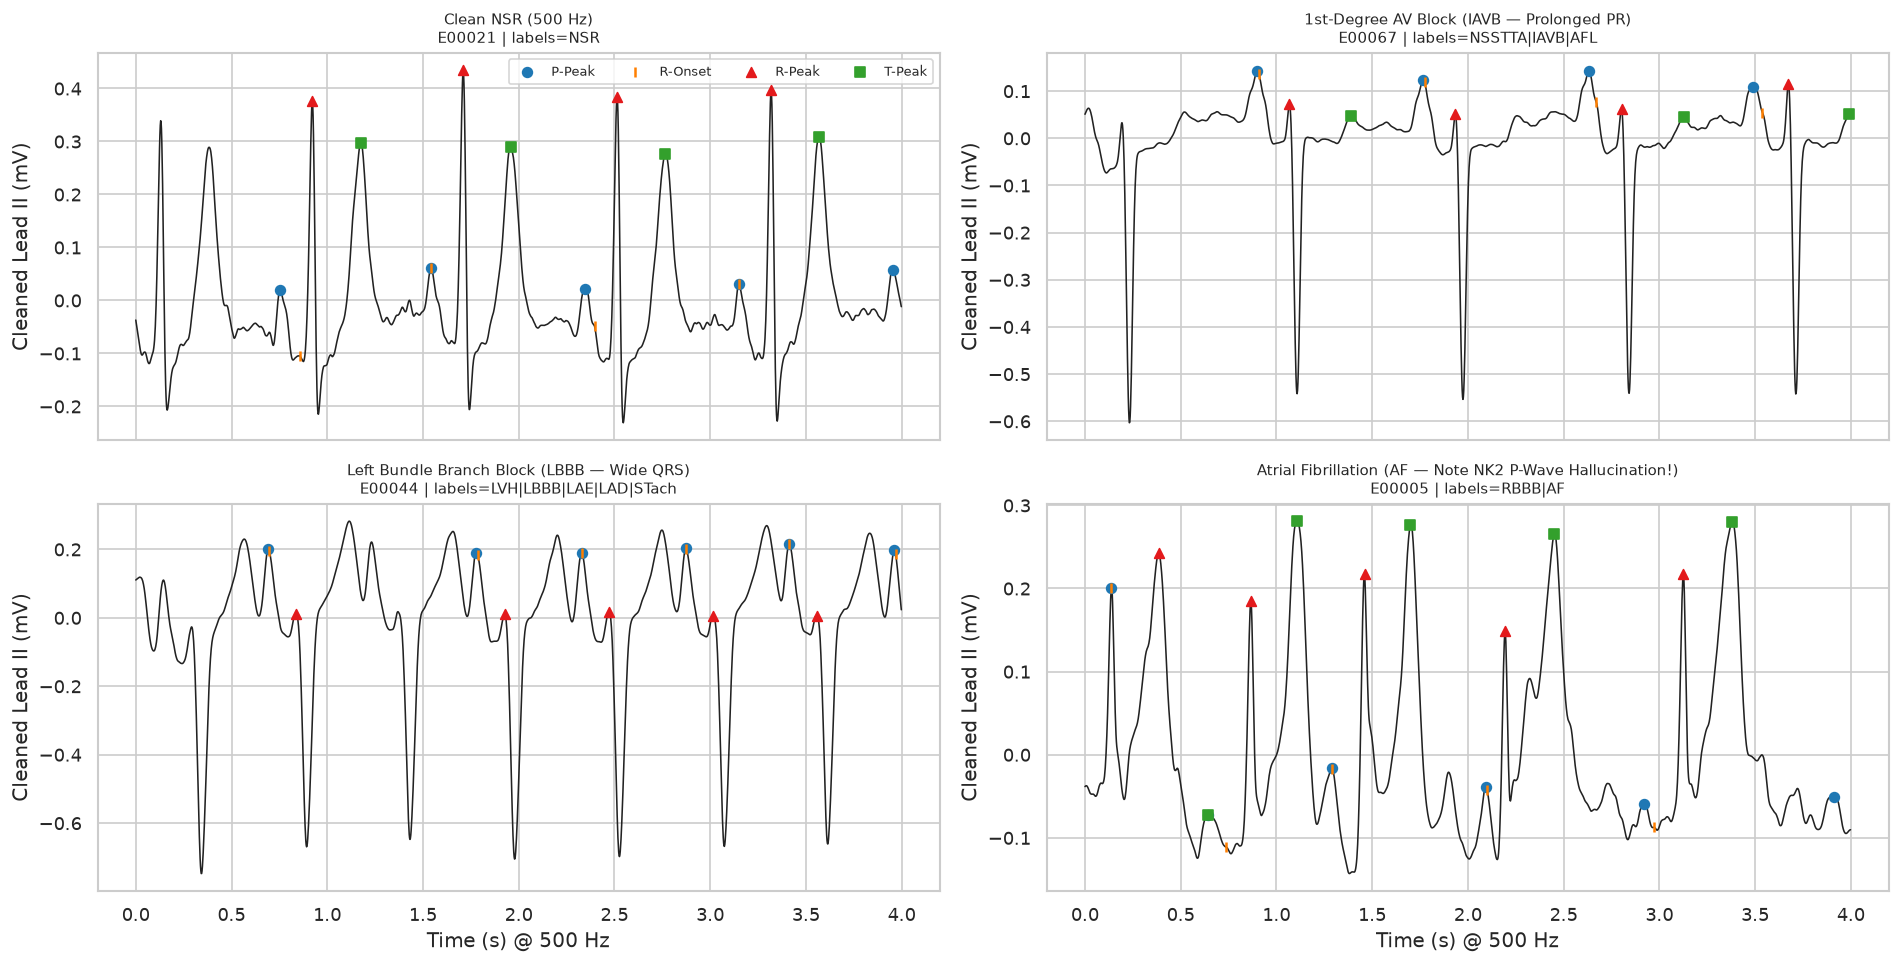

In [3]:
# Visual 4-Panel NeuroKit2 500 Hz Delineation Gallery (NSR, IAVB, LBBB, AF)
examples = [
    ("Clean NSR (500 Hz)", valid_df.index[valid_df["snomed_codes"].eq("426783006") & (valid_df["severity_tier"] == "0_clean")][0]),
    ("1st-Degree AV Block (IAVB — Prolonged PR)", valid_df.index[valid_df["snomed_codes"].str.contains("270492004") & (valid_df["severity_tier"] == "0_clean")][0]),
    ("Left Bundle Branch Block (LBBB — Wide QRS)", valid_df.index[valid_df["snomed_codes"].str.contains("164909002") & (valid_df["severity_tier"] == "0_clean")][0]),
    ("Atrial Fibrillation (AF — Note NK2 P-Wave Hallucination!)", valid_df.index[valid_df["snomed_codes"].str.contains("164889003") & (valid_df["severity_tier"] == "0_clean")][0]),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 8.2), sharex=True)
axes = axes.ravel()
T_WIN = 2000  # 4.0 seconds @ 500 Hz
t = np.arange(T_WIN) / 500.0

for ax, (title, rid) in zip(axes, examples):
    sig, _ = wfdb.rdsamp(str(DATA_DIR / valid_df.loc[rid, "record_path"]))
    w_l2 = np.nan_to_num(sig[:, 1])
    cleaned = nk.ecg_clean(w_l2, sampling_rate=500, method="neurokit")
    _, r_info = nk.ecg_peaks(cleaned, sampling_rate=500)
    rpeaks = np.asarray(r_info["ECG_R_Peaks"], dtype=int)
    _, waves = nk.ecg_delineate(cleaned, rpeaks, sampling_rate=500, method="dwt")

    ax.plot(t, cleaned[:T_WIN], color="#222222", lw=0.95)
    for lbl, key, col, mk in [
        ("P-Peak", "ECG_P_Peaks", "#1f78b4", "o"),
        ("R-Onset", "ECG_R_Onsets", "#ff7f00", "|"),
        ("R-Peak", None, "#e31a1c", "^"),
        ("T-Peak", "ECG_T_Peaks", "#33a02c", "s"),
    ]:
        pts = rpeaks if key is None else np.array([int(v) for v in waves.get(key, []) if pd.notna(v)], dtype=int)
        pts = pts[pts < T_WIN]
        if len(pts):
            ax.scatter(pts / 500.0, cleaned[pts], color=col, marker=mk, s=34, zorder=4, label=lbl)
    ax.set_title(f"{title}\n{rid} | labels={valid_df.loc[rid, 'label_names']}", fontsize=9.2)
    ax.set_ylabel("Cleaned Lead II (mV)")

axes[0].legend(loc="upper right", ncol=4, fontsize=8)
axes[2].set_xlabel("Time (s) @ 500 Hz")
axes[3].set_xlabel("Time (s) @ 500 Hz")
plt.tight_layout()
plt.show()